In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

In [2]:
rng=np.random.default_rng(42)
n_plants,n_markers=500,100
X=rng.integers(0,3,size=(n_plants,n_markers))
markers=[f"Marker_{i+1:03d}" for i in range(n_markers)]
effects=np.zeros(n_markers); effects[[5,18,37,64,82]]=[1.8,-1.4,1.2,1.6,-1.0]
yield_value=50+X@effects+rng.normal(0,2.5,n_plants)
df=pd.DataFrame(X,columns=markers); df["Yield"]=yield_value
display(df.head()); print("Shape:",df.shape)

,Marker_001,Marker_002,Marker_003,Marker_004,Marker_005,Marker_006,Marker_007,Marker_008,Marker_009,Marker_010,...,Marker_092,Marker_093,Marker_094,Marker_095,Marker_096,Marker_097,Marker_098,Marker_099,Marker_100,Yield
0,0,2,1,1,1,2,0,2,0,0,...,2,2,1,2,0,0,2,1,0,52.247304
1,2,0,2,0,2,2,2,1,1,2,...,1,1,1,2,0,1,0,1,2,52.689918
2,1,2,1,2,1,0,2,2,0,2,...,0,2,0,1,1,2,1,0,0,52.334838
3,1,2,0,2,1,0,0,1,0,0,...,0,1,1,2,2,0,0,0,0,45.140410
4,2,2,0,2,1,1,1,0,2,0,...,2,2,1,0,1,0,1,2,1,53.006993


Shape: (500, 101)


Missing values: 0


,Yield
count,500.000000
mean,52.354967
std,3.701099
min,40.779222
25%,49.901240
50%,52.201145
75%,54.970736
max,64.890506


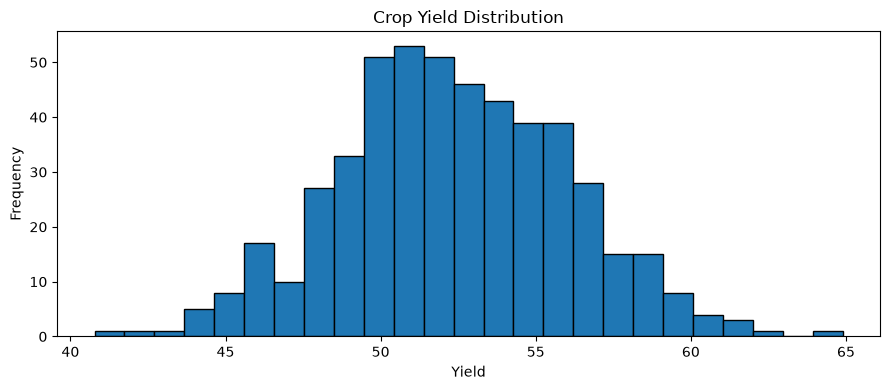

In [3]:
print("Missing values:",df.isna().sum().sum())
display(df.Yield.describe().to_frame("Yield"))
plt.figure(figsize=(9,4)); plt.hist(df.Yield,bins=25,edgecolor="black")
plt.title("Crop Yield Distribution"); plt.xlabel("Yield"); plt.ylabel("Frequency"); plt.tight_layout(); plt.show()

,Marker,Correlation,Absolute_Correlation
5,Marker_006,0.434544,0.434544
64,Marker_065,0.353566,0.353566
18,Marker_019,-0.304629,0.304629
82,Marker_083,-0.264839,0.264839
37,Marker_038,0.227802,0.227802
30,Marker_031,-0.130347,0.130347
36,Marker_037,-0.111096,0.111096
11,Marker_012,-0.096864,0.096864
33,Marker_034,-0.093227,0.093227
25,Marker_026,-0.090650,0.090650


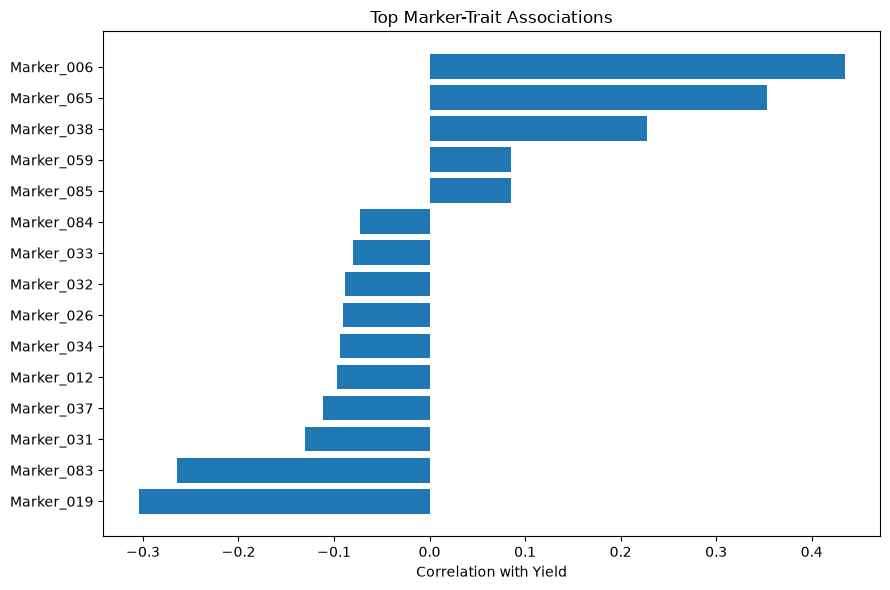

In [4]:
# Marker-Trait Association Screening
corr=df[markers].corrwith(df.Yield)
assoc=pd.DataFrame({"Marker":corr.index,"Correlation":corr.values,"Absolute_Correlation":np.abs(corr.values)}).sort_values("Absolute_Correlation",ascending=False)
display(assoc.head(15))
top=assoc.head(15).sort_values("Correlation")
plt.figure(figsize=(9,6)); plt.barh(top.Marker,top.Correlation)
plt.title("Top Marker-Trait Associations"); plt.xlabel("Correlation with Yield"); plt.tight_layout(); plt.show()

In [5]:
# Random Forest Model Traning and Prediction.
X_train,X_test,y_train,y_test=train_test_split(df[markers],df.Yield,test_size=.2,random_state=42)
model=RandomForestRegressor(n_estimators=300,max_features="sqrt",random_state=42)
model.fit(X_train,y_train); pred=model.predict(X_test)
mae=mean_absolute_error(y_test,pred); rmse=np.sqrt(mean_squared_error(y_test,pred)); r2=r2_score(y_test,pred)
print(f"MAE: {mae:.4f}\nRMSE: {rmse:.4f}\nR²: {r2:.4f}")

MAE: 2.5349
RMSE: 3.1495
R²: 0.2558


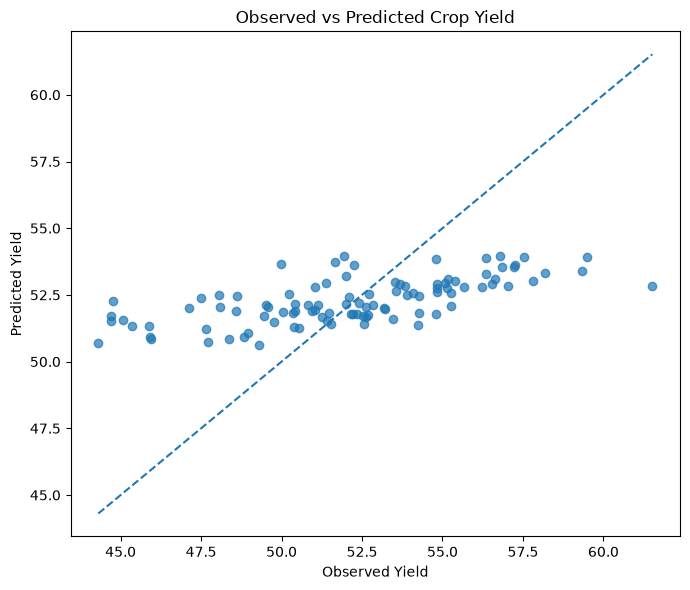

In [6]:
plt.figure(figsize=(7,6)); plt.scatter(y_test,pred,alpha=.7)
lo=min(y_test.min(),pred.min()); hi=max(y_test.max(),pred.max())
plt.plot([lo,hi],[lo,hi],"--")
plt.title("Observed vs Predicted Crop Yield"); plt.xlabel("Observed Yield"); plt.ylabel("Predicted Yield"); plt.tight_layout(); plt.show()